# 05 Simulation: the IP against simpler methods

**Question.** Over whole sessions, how does the IP compare with the human-made alternatives
(`chronological`, the chat-sidebar status quo, and `greedy`), with the judge's own top choice
(`judge_argmax`, `judge_restructure`) and with an IP without stability costs
(`ip_full_recluster`)? Does the IP ever decide differently from the judge's argmax, i.e. is the
problem non-trivial?

Every method starts from an empty forest and places the prompts in order. After every step the
forest is validated and saved to `outputs/forests/<session>/<method>/step_XX.json`.

**Metrics** (`forest/metrics.py`) are the same for every method:
- **fit** is the calibrated cosine of each prompt to its topic's label, summed. It is one scorer
  for all methods: no judge scores, and a topic named after its prompts scores higher.
- **hier fit** is the same cosine between a topic's label and its parent's label.
- **imbalance** counts topics with more than `U` prompts (`over_U`) or less than `L` content
  (`under_L`).
- **disruption** is the prompts and categories moved, removed or renamed, weighted by `w` and
  `v`.
- **violations** count breaches of the IP's hard limits (`K_T` trees per group, `K_G` groups).
- **ari** is the adjusted Rand index of the topic, tree and group partitions against the draft
  gold labels.

**Caveat.** The judge is the offline stand-in, and the gold labels are drafts.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from forest import config, viz
from forest.export import export_sequence
from forest.io import SESSION_IDS, load_gold, load_sessions, read_jsonl
from forest.simulate import ALL_METHODS, compare, make_context

viz.style()
pd.set_option("display.width", 200)
cfg = config.load()
ctx = make_context(cfg)
sessions = load_sessions()
golds = {sid: load_gold(sid) for sid in SESSION_IDS}
FIG, MET, FOR = (Path(cfg["paths"][k]) for k in ("figures", "metrics", "forests"))

In [2]:
all_steps, all_summary, all_forests = [], [], {}
for sid, s in sessions.items():
    steps, summary, forests = compare(list(ALL_METHODS), s, ctx, golds[sid], save_root=FOR)
    all_steps.append(steps)
    all_summary.append(summary)
    all_forests[sid] = forests
steps = pd.concat(all_steps, ignore_index=True)
summary = pd.concat(all_summary, ignore_index=True)
steps.drop(columns=["sizes"]).to_csv(MET / "05_steps.csv", index=False)
summary.to_csv(MET / "05_summary.csv", index=False)
print(f"{len(steps)} steps; every forest validated (run() raises otherwise)")

Restricted license - for non-production use only - expires 2028-11-29


510 steps; every forest validated (run() raises otherwise)


## Comparison per session

In [3]:
COLS = ["method", "final_fit", "final_hier_fit", "topics", "trees", "groups", "over_U", "under_L",
        "viol_K_T", "viol_K_G", "moved_prompts", "steps_changed", "disruption_w", "ari_topic", "ari_tree",
        "ari_group", "actions"]
for sid in SESSION_IDS:
    print(f"=== {sid}")
    display(summary[summary["session"] == sid][COLS].round(2).set_index("method"))

=== s1_focused


,final_fit,final_hier_fit,topics,trees,groups,over_U,under_L,viol_K_T,viol_K_G,moved_prompts,steps_changed,disruption_w,ari_topic,ari_tree,ari_group,actions
method,,,,,,,,,,,,,,,,
chronological,8.42,1.59,2,2,1,2,0,0,0,0,0,0.00,0.01,0.15,1.0,a:28 c:1 d:1
greedy,26.82,7.08,15,12,2,0,6,7,0,0,0,0.00,0.41,0.14,0.0,a:15 b:3 c:10 d:2
judge_argmax,28.77,8.86,21,10,2,0,11,5,0,0,0,0.00,0.30,0.18,0.0,a:9 b:11 c:8 d:2
judge_restructure,28.63,7.71,15,15,6,1,8,5,1,21,3,66.59,0.50,0.17,0.0,a:8 b:9 c:8 d:2 e:3
ip_full_recluster,28.51,12.23,22,8,2,0,2,0,0,42,24,182.13,0.16,0.30,0.0,a:2 b:1 c:1 d:2 e:24
ip,23.67,8.14,15,4,1,0,4,0,0,0,0,0.00,0.30,0.22,1.0,a:15 b:11 c:3 d:1


=== s2_mixed


,final_fit,final_hier_fit,topics,trees,groups,over_U,under_L,viol_K_T,viol_K_G,moved_prompts,steps_changed,disruption_w,ari_topic,ari_tree,ari_group,actions
method,,,,,,,,,,,,,,,,
chronological,5.27,1.31,2,2,1,2,0,0,0,0,0,0.00,-0.02,-0.03,0.00,a:28 c:1 d:1
greedy,26.12,7.67,19,18,3,0,11,12,0,0,0,0.00,0.41,0.40,-0.00,a:11 b:1 c:15 d:3
judge_argmax,28.39,13.21,26,15,3,0,18,9,0,0,0,0.00,0.19,0.32,-0.00,a:4 b:11 c:12 d:3
judge_restructure,28.34,12.33,21,21,8,0,14,4,3,8,3,50.66,0.41,0.33,0.47,a:5 b:7 c:13 d:2 e:3
ip_full_recluster,27.82,12.35,22,9,3,0,3,0,0,19,20,77.78,0.32,0.40,0.49,a:3 b:2 c:3 d:2 e:20
ip,19.03,8.04,12,5,2,0,0,0,0,2,3,3.14,0.32,0.27,0.01,a:16 b:6 c:3 d:2 e:3


=== s3_drift


,final_fit,final_hier_fit,topics,trees,groups,over_U,under_L,viol_K_T,viol_K_G,moved_prompts,steps_changed,disruption_w,ari_topic,ari_tree,ari_group,actions
method,,,,,,,,,,,,,,,,
chronological,7.34,1.52,2,2,1,2,0,0,0,0,0,0.00,0.20,0.78,1.0,a:23 c:1 d:1
greedy,23.61,6.51,17,15,2,0,9,9,0,0,0,0.00,0.51,0.12,0.0,a:8 b:2 c:13 d:2
judge_argmax,23.95,7.96,19,15,2,0,11,9,0,0,0,0.00,0.44,0.12,0.0,a:6 b:4 c:13 d:2
judge_restructure,23.95,11.20,19,17,7,0,13,1,2,0,2,23.78,0.44,0.11,0.0,a:4 b:4 c:13 d:2 e:2
ip_full_recluster,22.59,7.16,16,4,1,0,1,0,0,18,17,90.89,0.36,0.25,1.0,a:6 c:1 d:1 e:17
ip,16.23,4.76,10,4,1,1,1,0,0,1,1,1.05,0.06,0.17,1.0,a:14 b:6 c:3 d:1 e:1


## Is the problem non-trivial?
`ip_differs_from_judge_argmax` is the share of steps where the IP put the prompt somewhere
other than the judge's top-rated option, given the same judge answer. It is counterfactual:
both decisions are compared on the IP's own trajectory.

In [4]:
nontrivial = summary[summary["method"].isin(["ip", "ip_full_recluster"])][["session", "method", "ip_differs_from_judge_argmax"]]
nontrivial.pivot(index="session", columns="method", values="ip_differs_from_judge_argmax").round(3)

method,ip,ip_full_recluster
session,,
s1_focused,0.467,0.333
s2_mixed,0.600,0.233
s3_drift,0.800,0.400


## Over the steps

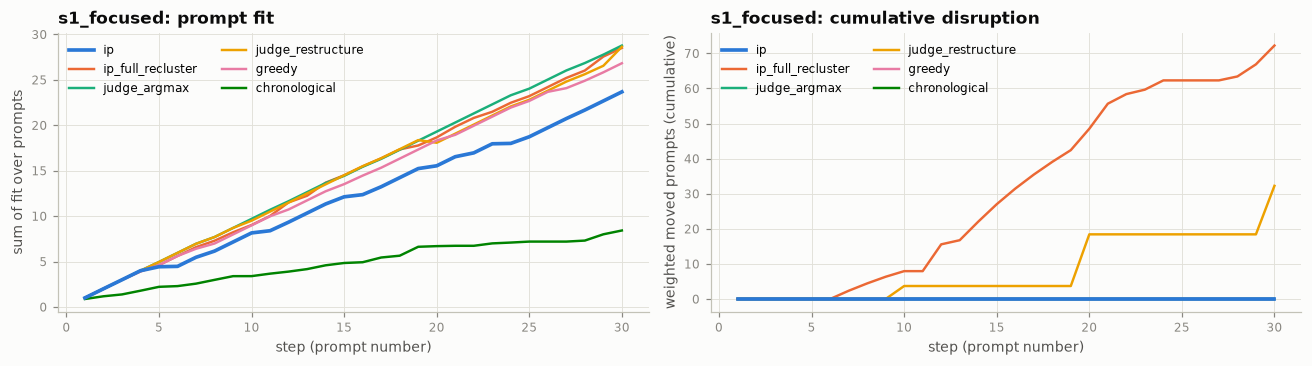

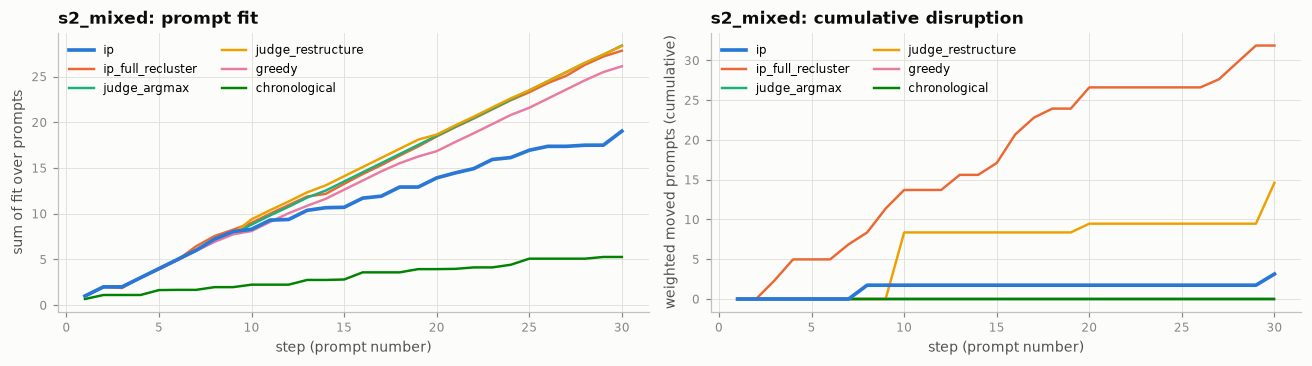

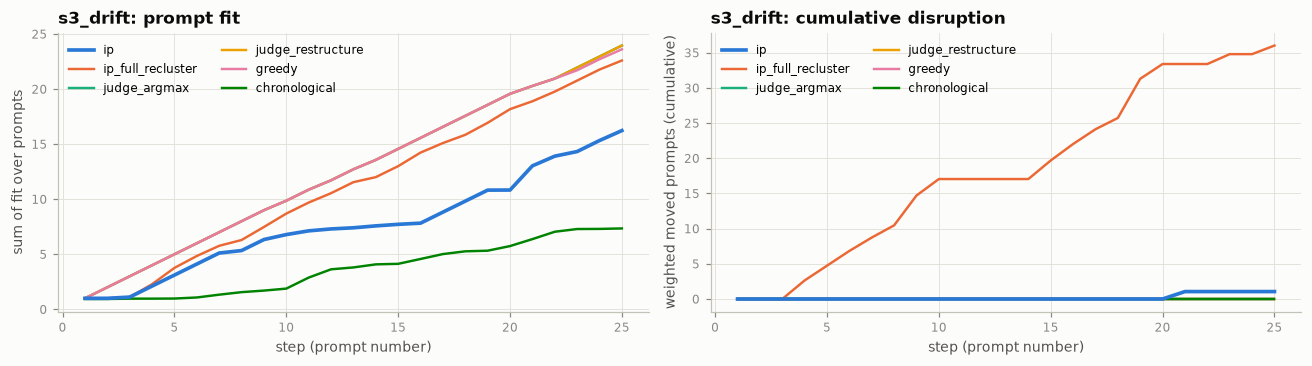

In [5]:
for sid in SESSION_IDS:
    d = steps[steps["session"] == sid]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    viz.line_by_method(d, "fit", axes[0], title=f"{sid}: prompt fit", ylabel="sum of fit over prompts")
    viz.line_by_method(d, "moved_prompts_w", axes[1], title=f"{sid}: cumulative disruption",
                       ylabel="weighted moved prompts (cumulative)", cumulative=True)
    fig.tight_layout()
    viz.save(fig, FIG / f"05_{sid}_fit_disruption.png")

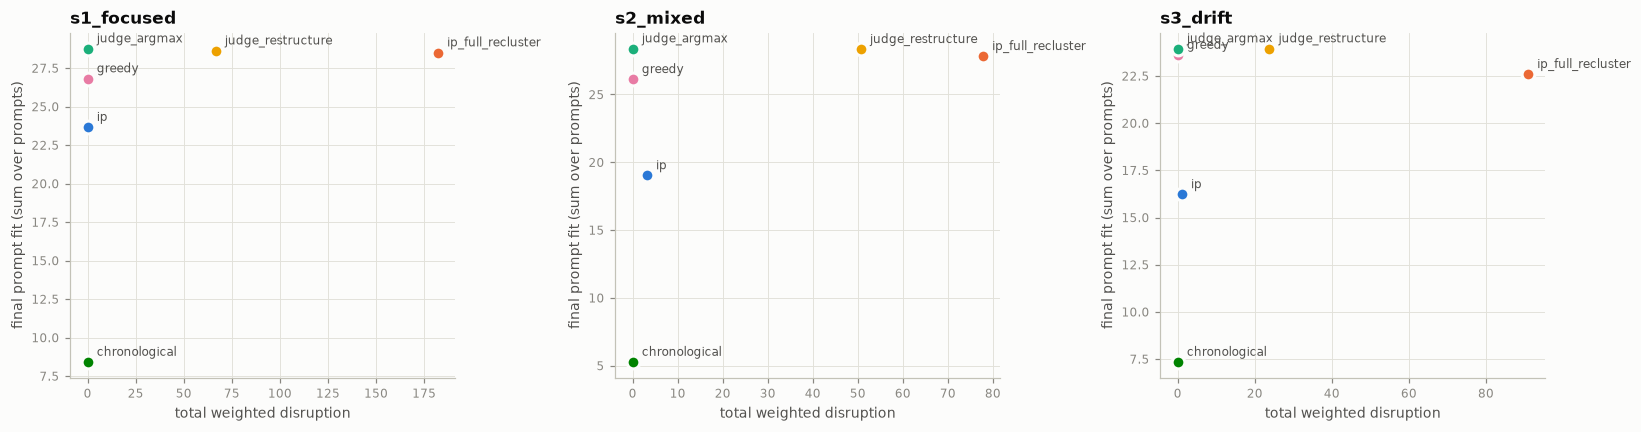

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sid in zip(axes, SESSION_IDS):
    viz.fit_vs_disruption(summary[summary["session"] == sid], ax, title=sid)
    ax.set_xlabel("total weighted disruption")
fig.tight_layout()
viz.save(fig, FIG / "05_fit_vs_disruption.png")

## Where the IP and the judge's argmax part ways
Side by side, after the first steps where the IP's decision differs from the argmax. The forests
are those of the two methods' own runs, so they also differ by everything that happened before.

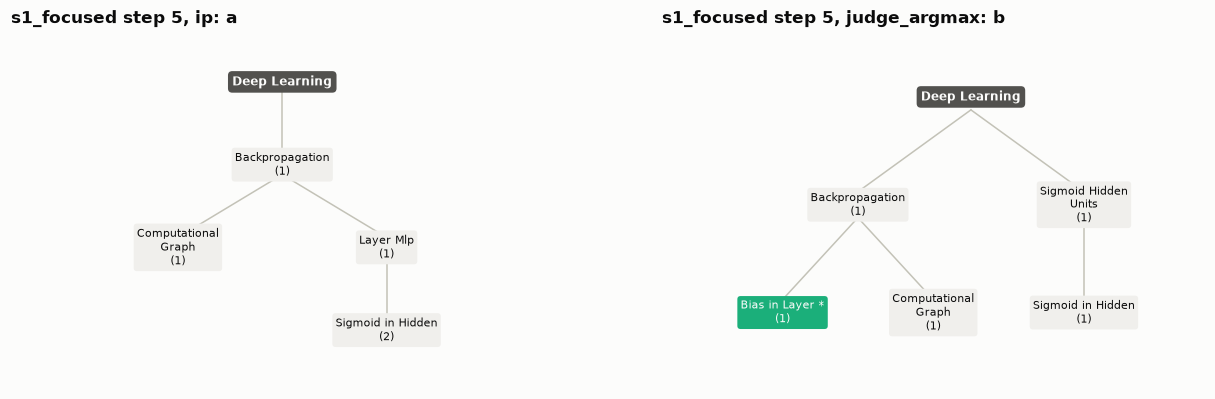

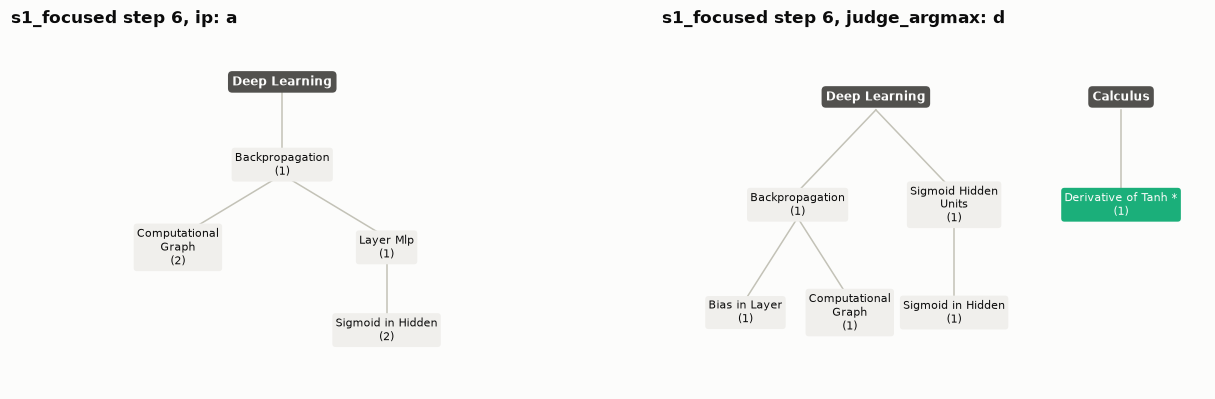

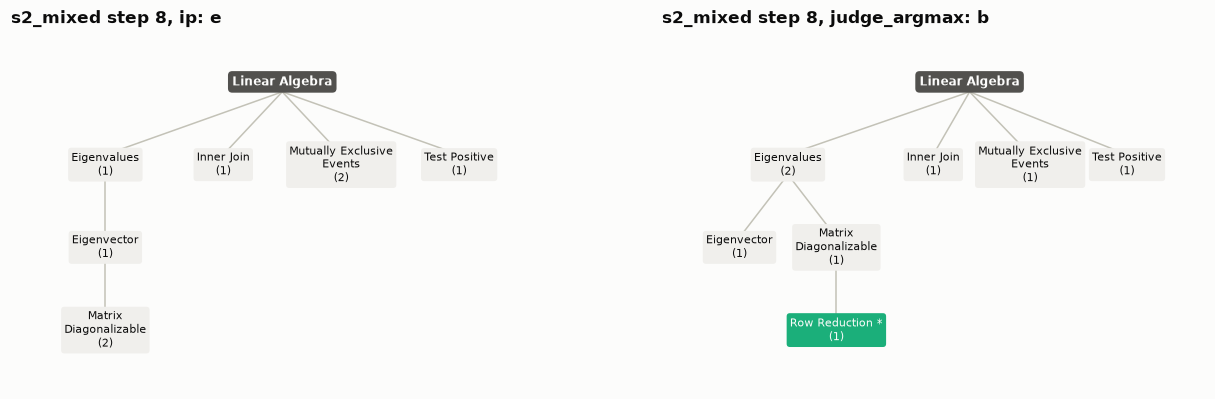

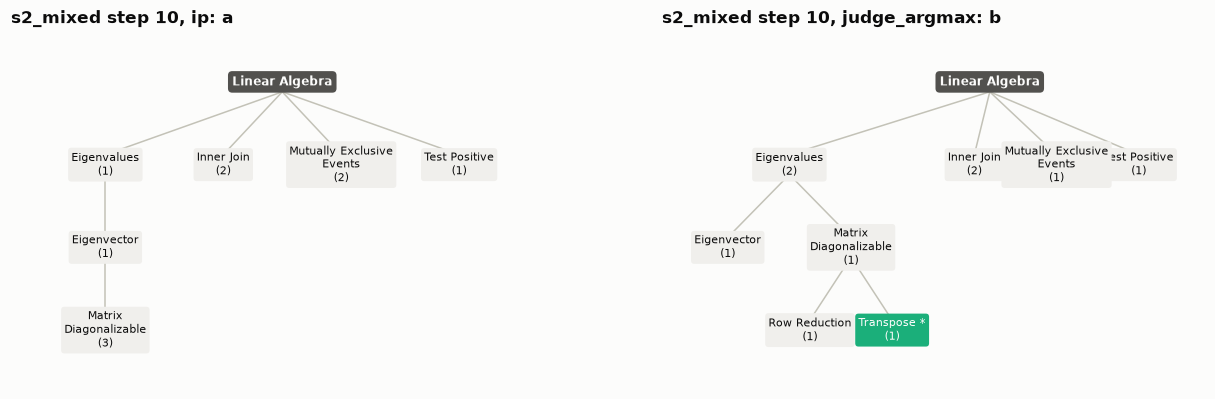

In [7]:
for sid in ["s1_focused", "s2_mixed"]:
    d = steps[(steps["session"] == sid) & (steps["method"] == "ip")]
    diff_steps = d[d["same_as_argmax"] == False]["step"].tolist()  # noqa: E712
    picks = diff_steps[1:3] if len(diff_steps) > 2 else diff_steps[:2]
    for st in picks:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
        for ax, m in zip(axes, ["ip", "judge_argmax"]):
            f = all_forests[sid][m][st - 1]
            prev = all_forests[sid][m][st - 2]
            row = steps[(steps["session"] == sid) & (steps["method"] == m) & (steps["step"] == st)].iloc[0]
            viz.plot_forest(f, ax, title=f"{sid} step {st}, {m}: {row['action']}", **viz.forest_change_sets(prev, f))
        viz.save(fig, FIG / f"05_{sid}_step{st:02d}_ip_vs_argmax.png")
        plt.show()

## Export for the prototype
The forest after every step of every method, in the app's data model (concepts, trees, attempts,
messages; see `forest/export.py`), plus each step's decision. The A/B condition of Milestone 4
loads `outputs/forests/<session>/ip/app_sequence.json`.

In [8]:
for sid in SESSION_IDS:
    for m in ALL_METHODS:
        out = FOR / sid / m
        decisions = read_jsonl(out / "decisions.jsonl")
        export_sequence(all_forests[sid][m], decisions, out, {"session": sid, "method": m, "judge": ctx.judge.model,
                                                              "embedding": ctx.emb.model})
print("exported", sorted(p.relative_to(ROOT).as_posix() for p in FOR.glob("*/ip/app_*.json")))

exported ['outputs/forests/s1_focused/ip/app_final.json', 'outputs/forests/s1_focused/ip/app_sequence.json', 'outputs/forests/s2_mixed/ip/app_final.json', 'outputs/forests/s2_mixed/ip/app_sequence.json', 'outputs/forests/s3_drift/ip/app_final.json', 'outputs/forests/s3_drift/ip/app_sequence.json']


## Numbers for the findings

In [9]:
key = summary.set_index(["session", "method"])
for sid in SESSION_IDS:
    k = key.loc[sid]
    print(f"{sid}: ip fit {k.loc['ip', 'final_fit']:.1f} vs argmax {k.loc['judge_argmax', 'final_fit']:.1f} vs "
          f"greedy {k.loc['greedy', 'final_fit']:.1f} vs chronological {k.loc['chronological', 'final_fit']:.1f}; "
          f"topics ip {k.loc['ip', 'topics']} argmax {k.loc['judge_argmax', 'topics']}; "
          f"K_T violations greedy {k.loc['greedy', 'viol_K_T']} argmax {k.loc['judge_argmax', 'viol_K_T']}; "
          f"disruption ip {k.loc['ip', 'disruption_w']:.1f} full {k.loc['ip_full_recluster', 'disruption_w']:.1f} "
          f"restructure {k.loc['judge_restructure', 'disruption_w']:.1f}; "
          f"differs {k.loc['ip', 'ip_differs_from_judge_argmax']:.2f}")

s1_focused: ip fit 23.7 vs argmax 28.8 vs greedy 26.8 vs chronological 8.4; topics ip 15 argmax 21; K_T violations greedy 7 argmax 5; disruption ip 0.0 full 182.1 restructure 66.6; differs 0.47
s2_mixed: ip fit 19.0 vs argmax 28.4 vs greedy 26.1 vs chronological 5.3; topics ip 12 argmax 26; K_T violations greedy 12 argmax 9; disruption ip 3.1 full 77.8 restructure 50.7; differs 0.60
s3_drift: ip fit 16.2 vs argmax 24.0 vs greedy 23.6 vs chronological 7.3; topics ip 10 argmax 19; K_T violations greedy 9 argmax 9; disruption ip 1.1 full 90.9 restructure 23.8; differs 0.80


## Findings

- All six methods ran on all three sessions, and every one of the 510 forests validated.
- **Non-trivial:** given the same judge answer, the IP placed the prompt elsewhere than the
  judge's argmax in 47 %, 60 % and 80 % of the steps (s1, s2, s3). The IP without stability
  costs did so in 23 to 40 %.
- **Fit:** on the shared label-cosine fit, the IP scores below the judge-based baselines
  (s1 23.7 vs 28.8 for `judge_argmax`, s2 19.0 vs 28.4, s3 16.2 vs 24.0) but far above the
  chat-sidebar status quo (`chronological`: 8.4, 5.3, 7.3). It also builds far fewer topics
  (15, 12, 10 vs 21, 26, 19). This metric rewards many topics named after their own prompts,
  which the IP prices with `lam` and `L`.
- **Structure and stability:** the IP never breaks the tree limit `K_T`, while `greedy` and
  `judge_argmax` exceed it by 5 to 12 trees per session and leave 6 to 18 topics below `L`. The
  IP moved at most 2 old prompts per session (weighted disruption 0 to 3.1). The IP without
  stability costs moved 18 to 42 (78 to 182), and the periodic judge restructure up to 21 (24 to 67).
- **Gold agreement (draft labels):** mixed. Topic ARI for the IP is 0.30, 0.32 and 0.06, against
  0.30, 0.19 and 0.44 for `judge_argmax`. The drifting session is the IP's weak case with the
  stand-in judge.
- *Caveat:* offline stand-in judge, draft gold labels. Re-run with a live judge before quoting
  any of this. The group's interpretation goes here.